# Delivery Duration Prediction

Predict how many minutes a food delivery will take, at the moment a courier is assigned to the order, using the restaurant and
delivery coordinates, order time, weather, traffic, order type, festival and city, and the assigned courier's age, rating,
vehicle, vehicle condition and number of other deliveries carried. The model is served as an API so a delivery platform can show
the customer an ETA and plan dispatch. See `README.md`.

## 1. Data preparation

- Load the dataset with pandas
- Inspect columns, data types, and unique values
- Clean strings and numbers, parse dates/times, fix flipped coordinate signs, then compute distance
- Filter out invalid coordinates/distances and records with a missing festival flag

In [84]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [85]:
df = pd.read_csv('data/raw/train.csv')
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [86]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'restaurant_latitude',
       'restaurant_longitude', 'delivery_location_latitude',
       'delivery_location_longitude', 'order_date', 'time_orderd',
       'time_order_picked', 'weatherconditions', 'road_traffic_density',
       'vehicle_condition', 'type_of_order', 'type_of_vehicle',
       'multiple_deliveries', 'festival', 'city', 'time_taken(min)'],
      dtype='object')

In [87]:
for col in df.columns:
	print(col)
	print(df[col].unique()[:5])
	print(df[col].nunique())
	print()

id
['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ']
45593

delivery_person_id
['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ']
1320

delivery_person_age
['37' '34' '23' '38' '32']
23

delivery_person_ratings
['4.9' '4.5' '4.4' '4.7' '4.6']
29

restaurant_latitude
[22.745049 12.913041 12.914264 11.003669 12.972793]
657

restaurant_longitude
[75.892471 77.683237 77.6784   76.976494 80.249982]
518

delivery_location_latitude
[22.765049 13.043041 12.924264 11.053669 13.012793]
4373

delivery_location_longitude
[75.912471 77.813237 77.6884   77.026494 80.289982]
4373

order_date
['19-03-2022' '25-03-2022' '05-04-2022' '26-03-2022' '11-03-2022']
44

time_orderd
['11:30:00' '19:45:00' '08:30:00' '18:00:00' '13:30:00']
177

time_order_picked
['11:45:00' '19:50:00' '08:45:00' '18:10:00' '13:45:00']
193

weatherconditions
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog']
7

road_traffic_density
[

In [88]:
df.dtypes

id                              object
delivery_person_id              object
delivery_person_age             object
delivery_person_ratings         object
restaurant_latitude            float64
restaurant_longitude           float64
delivery_location_latitude     float64
delivery_location_longitude    float64
order_date                      object
time_orderd                     object
time_order_picked               object
weatherconditions               object
road_traffic_density            object
vehicle_condition                int64
type_of_order                   object
type_of_vehicle                 object
multiple_deliveries             object
festival                        object
city                            object
time_taken(min)                 object
dtype: object

In [89]:
df['id'] = df['id'].astype(str).str.strip()
df = df.drop_duplicates()

df['time_taken(min)'] = df['time_taken(min)'].str.replace('(min)', '')
df['duration'] = pd.to_numeric(df['time_taken(min)'], errors='coerce')

categorical_map = {'weatherconditions': 'weather', 'road_traffic_density': 'traffic',
                   'type_of_vehicle': 'vehicle', 'type_of_order': 'order_type',
                   'festival': 'festival', 'city': 'city'}

for src, dest in categorical_map.items():
	df[dest] = (df[src].astype(str).str.strip().str.lower().str.removeprefix('conditions').str.strip().str.replace(' ', '_'))
	df[dest] = df[dest].replace({'': 'unknown', 'nan': 'unknown', 'none': 'unknown', 'metropolitian': 'metropolitan'})

courier_numerical = ['delivery_person_age', 'delivery_person_ratings', 'multiple_deliveries']
for col in courier_numerical:
	df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

# Ratings are on a 1-5 scale; 6.0 occurs only for one placeholder courier group (age 50), so it is treated as missing.
print("Ratings above 5:", (df['delivery_person_ratings'] > 5).sum())
df.loc[df['delivery_person_ratings'] > 5, 'delivery_person_ratings'] = np.nan

df[['id', 'weather', 'traffic', 'vehicle', 'order_type', 'festival', 'city'] + courier_numerical + ['duration']].head()

Ratings above 5: 53


,id,weather,traffic,vehicle,order_type,festival,city,delivery_person_age,delivery_person_ratings,multiple_deliveries,duration
0,0x4607,sunny,high,motorcycle,snack,no,urban,37.0,4.9,0.0,24
1,0xb379,stormy,jam,scooter,snack,no,metropolitan,34.0,4.5,1.0,33
2,0x5d6d,sandstorms,low,motorcycle,drinks,no,urban,23.0,4.4,1.0,26
3,0x7a6a,sunny,medium,motorcycle,buffet,no,metropolitan,38.0,4.7,1.0,21
4,0x70a2,cloudy,high,scooter,snack,no,metropolitan,32.0,4.6,1.0,30


In [90]:
for col in ["weather", "traffic", "vehicle", "order_type", "festival", "city"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))
    print("Unknown percentage:",
          f"{df[col].eq('unknown').mean() * 100:.2f}%")


weather
weather
fog           7654
stormy        7586
cloudy        7536
sandstorms    7495
windy         7422
sunny         7284
unknown        616
Name: count, dtype: int64
Unknown percentage: 1.35%

traffic
traffic
low        15477
jam        14143
medium     10947
high        4425
unknown      601
Name: count, dtype: int64
Unknown percentage: 1.32%

vehicle
vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64
Unknown percentage: 0.00%

order_type
order_type
snack     11533
meal      11458
drinks    11322
buffet    11280
Name: count, dtype: int64
Unknown percentage: 0.00%

festival
festival
no         44469
yes          896
unknown      228
Name: count, dtype: int64
Unknown percentage: 0.50%

city
city
metropolitan    34093
urban           10136
unknown          1200
semi-urban        164
Name: count, dtype: int64
Unknown percentage: 2.63%


In [91]:
print("Duration of records with a missing festival flag:")
display(df.loc[df['festival'] == 'unknown', 'duration'].describe())
print("Missing courier values:")
display(df[courier_numerical].isna().sum())

Duration of records with a missing festival flag:


count    228.000000
mean      11.166667
std        1.234002
min       10.000000
25%       10.000000
50%       11.000000
75%       12.000000
max       14.000000
Name: duration, dtype: float64

Missing courier values:


delivery_person_age        1854
delivery_person_ratings    1961
multiple_deliveries         993
dtype: int64

In [92]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%d-%m-%Y', errors='coerce')
times = pd.to_datetime(df['time_orderd'].astype(str).str.strip(), format='%H:%M:%S', errors='coerce')

df['order_hour'] = times.dt.hour.fillna(-1).astype(int)
df['hour_missing'] = (df['order_hour'] == -1).astype(int)

df[['order_date', 'order_hour', 'hour_missing']].head()

,order_date,order_hour,hour_missing
0,2022-03-19,11,0
1,2022-03-25,19,0
2,2022-03-19,8,0
3,2022-04-05,18,0
4,2022-03-26,13,0


In [93]:
print("Raw CSV coordinate ranges (before cleaning):")
display(df[['restaurant_latitude', 'restaurant_longitude',
            'delivery_location_latitude', 'delivery_location_longitude']].describe().loc[['min', 'max']])

Raw CSV coordinate ranges (before cleaning):


,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude
min,-30.905562,-88.366217,0.010000,0.010000
max,30.914057,88.433452,31.054057,88.563452


In [94]:
df.loc[(df['restaurant_latitude'] < 0) | (df['restaurant_longitude'] < 0),
  ['restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude']
].head(10)

,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude
92,-27.163303,78.057044,27.233303,78.127044
283,-27.165108,78.015053,27.225108,78.075053
289,-18.551440,-73.804855,18.611440,73.864855
425,-30.366322,-78.070453,30.496322,78.200453
534,-12.325461,-76.632278,12.385461,76.692278
583,-12.316967,76.603067,12.326967,76.613067
762,-23.359194,-85.325447,23.449194,85.415447
1059,-26.477750,-80.351569,26.487750,80.361569
1091,-15.546594,73.760431,15.606594,73.820431
1157,-12.337978,76.616792,12.387978,76.666792


In [95]:
display(df['restaurant_latitude'].abs().describe())
display(df['restaurant_longitude'].abs().describe())

count    45593.000000
mean        17.401571
std          7.333766
min          0.000000
25%         12.934179
50%         18.554382
75%         22.732225
max         30.914057
Name: restaurant_latitude, dtype: float64

count    45593.000000
mean        70.782088
std         21.118611
min          0.000000
25%         73.170283
50%         75.898497
75%         78.046106
max         88.433452
Name: restaurant_longitude, dtype: float64

In [96]:
df['restaurant_latitude'] = df['restaurant_latitude'].abs()
df['restaurant_longitude'] = df['restaurant_longitude'].abs()

In [97]:
import math

def haversine_km(lat1, lon1, lat2, lon2):
	d_lat = math.radians(lat2 - lat1)
	d_lon = math.radians(lon2 - lon1)

	lat1 = math.radians(lat1)
	lat2 = math.radians(lat2)

	a = (math.sin(d_lat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(d_lon / 2) ** 2)

	earth_radius = 6371.0088

	c = 2 * math.asin(math.sqrt(min(1.0, max(0.0, a))))

	return earth_radius * c

df['distance_km'] = [
	haversine_km(r_lat, r_lon, d_lat, d_lon)
  for r_lat, r_lon, d_lat, d_lon in zip(df['restaurant_latitude'], df['restaurant_longitude'],
    df['delivery_location_latitude'], df['delivery_location_longitude'])
]

df[['distance_km', 'duration']].head()

,distance_km,duration
0,3.025153,24
1,20.183558,33
2,1.552760,26
3,7.790412,21
4,6.210147,30


In [ ]:
# import json
# from urllib.request import Request, urlopen

# url = "https://nominatim.openstreetmap.org/search?country=India&format=json"
# req = Request(url, headers={"User-Agent": "delivery-eta-project/1.0"})

# with urlopen(req, timeout=10) as response:
#     bbox = json.loads(response.read().decode())[0]["boundingbox"]
    
#     print("OpenStreetMap India Bounding Box:")
#     print(f"  Latitude : {float(bbox[0]):.2f} to {float(bbox[1]):.2f}  --> Project rule: [6, 36]")
#     print(f"  Longitude: {float(bbox[2]):.2f} to {float(bbox[3]):.2f} --> Project rule: [67, 98]\n")


OpenStreetMap India Bounding Box:
  Latitude : 6.55 to 35.67  --> Project rule: [6, 36]
  Longitude: 67.92 to 97.40 --> Project rule: [67, 98]



In [99]:
# Bounds used below: India's bounding box from OpenStreetMap Nominatim
# (lat 6.55-35.67, lon 67.92-97.40), rounded outward to lat [6, 36], lon [67, 98].

valid_coords = (
    df['restaurant_latitude'].between(6, 36) & df['restaurant_longitude'].between(67, 98) &
    df['delivery_location_latitude'].between(6, 36) & df['delivery_location_longitude'].between(67, 98)
)
valid_distance = (df['distance_km'] > 0) & (df['distance_km'] <= 100)
valid_target = df['duration'].notna() & (df['duration'] > 0)
valid_date = df['order_date'].notna()
valid_festival = df['festival'] != 'unknown'

df = df[valid_coords & valid_distance & valid_target & valid_date & valid_festival].copy()
df = df.sort_values(['order_date', 'id']).reset_index(drop=True)

print("Clean rows:", len(df))

Clean rows: 41738


In [100]:
df['weekend'] = (df['order_date'].dt.weekday >= 5).astype(int)
df['lunch'] = ((df['order_hour'] >= 11) & (df['order_hour'] < 14)).astype(int)
df['dinner'] = ((df['order_hour'] >= 17) & (df['order_hour'] < 21)).astype(int)

numerical = ['distance_km', 'order_hour', 'hour_missing', 'weekend', 'lunch', 'dinner',
             'delivery_person_age', 'delivery_person_ratings', 'vehicle_condition', 'multiple_deliveries']
categorical = ['weather', 'traffic', 'vehicle', 'order_type', 'festival', 'city']

df[numerical + categorical + ['duration']].head()

,distance_km,order_hour,hour_missing,weekend,lunch,dinner,delivery_person_age,delivery_person_ratings,vehicle_condition,multiple_deliveries,weather,traffic,vehicle,order_type,festival,city,duration
0,1.468903,-1,1,0,0,0,NaN,NaN,3,NaN,unknown,unknown,scooter,drinks,no,metropolitan,19
1,2.984672,-1,1,0,0,0,NaN,NaN,3,1.0,unknown,unknown,electric_scooter,snack,no,metropolitan,31
2,7.803089,-1,1,0,0,0,NaN,NaN,3,0.0,unknown,unknown,motorcycle,drinks,no,urban,16
3,1.465204,-1,1,0,0,0,NaN,NaN,3,0.0,unknown,unknown,bicycle,drinks,no,unknown,15
4,4.631698,-1,1,0,0,0,NaN,NaN,1,1.0,cloudy,low,motorcycle,snack,no,metropolitan,18


## 2. Setting up the validation framework
- Split 60% / 20% / 20% chronologically by unique `order_date`

In [101]:
days = np.sort(df['order_date'].unique())
n_days = len(days)

first = int(n_days * 0.6)
second = int(n_days * 0.8)

df_train = df[df['order_date'] < days[first]].copy()
df_val = df[(df['order_date'] >= days[first]) & (df['order_date'] < days[second])].copy()
df_test = df[df['order_date'] >= days[second]].copy()

df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

len(df_train), len(df_val), len(df_test)


(23927, 9010, 8801)

In [102]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.duration.values
y_val = df_val.duration.values
y_test = df_test.duration.values
y_full_train = df_full_train.duration.values

## 3. Exploratory Data Analysis (EDA)
Explore training dates (`df_train`) only:
- Summary statistics (ranges) of numerical and categorical features; missing values are encoded as `unknown` / `hour_missing`
- Target variable (`duration`) distribution
- Distance vs. duration relationship
- Feature importance: group mean ratios (the regression analogue of the risk ratio in Chapter 3), mutual information, and numerical correlations
- Missing values and the discrete courier columns (`multiple_deliveries`, `vehicle_condition`)

In [103]:
display(df_train[numerical + categorical].describe(include='all').T)

for col in categorical:
	print(col)
	print(df_train[col].value_counts(dropna=False))
	print(f"Unknown share: {df_train[col].eq('unknown').mean() * 100:.2f}%")
	print()

print(f"Missing order time share: {df_train.hour_missing.mean() * 100:.2f}%")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
distance_km,23927.0,NaN,NaN,NaN,9.764379,5.626432,1.465069,4.657679,9.193534,13.680939,20.969518
order_hour,23927.0,NaN,NaN,NaN,16.715802,5.904636,-1.0,13.0,19.0,21.0,23.0
hour_missing,23927.0,NaN,NaN,NaN,0.038868,0.193285,0.0,0.0,0.0,0.0,1.0
weekend,23927.0,NaN,NaN,NaN,0.229072,0.420244,0.0,0.0,0.0,0.0,1.0
lunch,23927.0,NaN,NaN,NaN,0.077778,0.267828,0.0,0.0,0.0,0.0,1.0
dinner,23927.0,NaN,NaN,NaN,0.396999,0.489286,0.0,0.0,0.0,1.0,1.0
delivery_person_age,22957.0,NaN,NaN,NaN,29.587141,5.817313,15.0,25.0,30.0,35.0,50.0
delivery_person_ratings,22879.0,NaN,NaN,NaN,4.630377,0.332964,1.0,4.5,4.7,4.9,5.0
vehicle_condition,23927.0,NaN,NaN,NaN,1.018055,0.840249,0.0,0.0,1.0,2.0,3.0
multiple_deliveries,23422.0,NaN,NaN,NaN,0.746136,0.572505,0.0,0.0,1.0,1.0,3.0


weather
weather
fog           4003
cloudy        3968
stormy        3966
sandstorms    3935
windy         3877
sunny         3854
unknown        324
Name: count, dtype: int64
Unknown share: 1.35%

traffic
traffic
low        8073
jam        7476
medium     5819
high       2249
unknown     310
Name: count, dtype: int64
Unknown share: 1.30%

vehicle
vehicle
motorcycle          13908
scooter              7998
electric_scooter     1984
bicycle                37
Name: count, dtype: int64
Unknown share: 0.00%

order_type
order_type
snack     6089
meal      5991
buffet    5988
drinks    5859
Name: count, dtype: int64
Unknown share: 0.00%

festival
festival
no     23468
yes      459
Name: count, dtype: int64
Unknown share: 0.00%

city
city
metropolitan    17934
urban            5292
unknown           625
semi-urban         76
Name: count, dtype: int64
Unknown share: 2.61%

Missing order time share: 3.89%


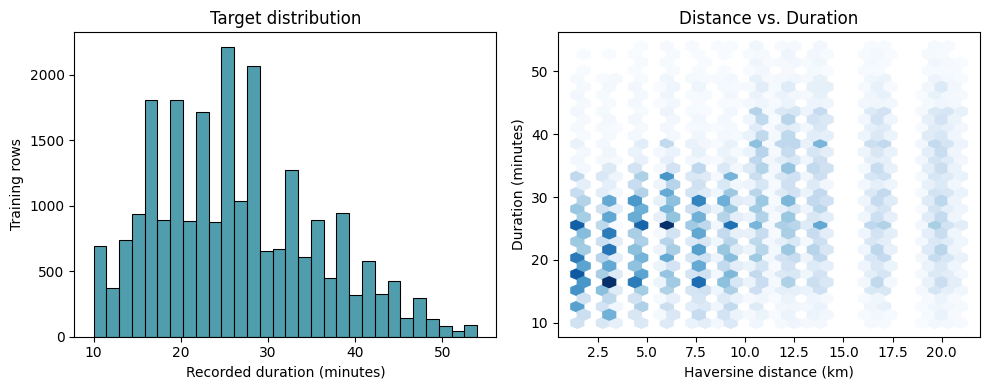

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(y_train, bins=30, color='#147d92', ax=axes[0])
axes[0].set(xlabel='Recorded duration (minutes)', ylabel='Training rows', title='Target distribution')
axes[1].hexbin(df_train.distance_km, y_train, gridsize=30, mincnt=1, cmap='Blues')
axes[1].set(xlabel='Haversine distance (km)', ylabel='Duration (minutes)', title='Distance vs. Duration')

plt.tight_layout()
plt.show()

**Target and distance.** Duration is bounded (roughly 10–54 minutes) with a mild right skew and no long tail,
so the raw minutes are used without a `log1p` transform.

In [77]:
for c in categorical:
    print(c)
    display(df_train.groupby(c).duration.agg(['count', 'mean', 'median']).sort_values('mean'))

weather


,count,mean,median
weather,,,
sunny,3812,22.153987,21.0
stormy,3932,25.958545,26.0
sandstorms,3892,26.022354,26.0
windy,3846,26.098284,26.0
unknown,233,26.600858,26.0
cloudy,3931,29.150598,29.0
fog,3964,29.189707,29.0


traffic


,count,mean,median
traffic,,,
low,7988,21.503255,21.0
unknown,221,26.533937,26.0
medium,5770,26.879376,27.0
high,2226,27.457323,27.0
jam,7405,31.171371,31.0


vehicle


,count,mean,median
vehicle,,,
electric_scooter,1945,24.678149,24.0
scooter,7888,24.695740,24.0
bicycle,27,26.925926,26.0
motorcycle,13750,27.719564,27.0


... (2 outputs left out)

festival


,count,mean,median
festival,,,
no,23154,26.086162,25.0
yes,456,45.331140,44.0


city


,count,mean,median
city,,,
unknown,613,22.481240,21.0
urban,5210,23.136660,22.0
metropolitan,17711,27.472362,27.0
semi-urban,76,49.789474,49.0


In [106]:
from sklearn.metrics import mutual_info_score

known_hour = df_train[df_train.hour_missing == 0]
print("Numerical correlation with duration:")
display(known_hour[[c for c in numerical if c != 'hour_missing'] + ['duration']].corr()['duration']
        .drop('duration').sort_values(ascending=False))
print("hour_missing vs. duration (all rows):", round(df_train.hour_missing.corr(df_train.duration), 3))

print("Mutual information score (categorical variables):")
def mutual_info_duration_score(series):
	return mutual_info_score(series, df_train.duration.astype(int))

mi = df_train[categorical].apply(mutual_info_duration_score)
display(mi.sort_values(ascending=False))

Numerical correlation with duration:


multiple_deliveries        0.383900
distance_km                0.321941
delivery_person_age        0.300859
dinner                     0.254249
order_hour                 0.185120
lunch                      0.017985
weekend                   -0.007391
vehicle_condition         -0.243374
delivery_person_ratings   -0.357012
Name: duration, dtype: float64

hour_missing vs. duration (all rows): -0.0
Mutual information score (categorical variables):


traffic       0.119451
weather       0.058495
festival      0.045141
city          0.037655
vehicle       0.022539
order_type    0.002942
dtype: float64

In [107]:
print("Missing values in model features (training rows):")
display(df_train[numerical + categorical].isna().sum().loc[lambda s: s > 0])

for c in ['multiple_deliveries', 'vehicle_condition']:
    print(c)
    display(df_train.groupby(c, dropna=False).duration.agg(['count', 'mean', 'median']))

Missing values in model features (training rows):


delivery_person_age         970
delivery_person_ratings    1048
multiple_deliveries         505
dtype: int64

multiple_deliveries


,count,mean,median
multiple_deliveries,,,
0.0,7385,23.126473,22.0
1.0,14779,26.930171,26.0
2.0,1077,40.439183,40.0
3.0,181,47.790055,48.0
NaN,505,23.148515,21.0


vehicle_condition


,count,mean,median
vehicle_condition,,,
0,7957,30.153575,28.0
1,7858,24.551158,24.0
2,7835,24.578047,24.0
3,277,26.205776,26.0


## 4. Model training and tuning
* Convert DataFrames to lists of dictionaries and encode with `DictVectorizer`
* Define regression evaluation metrics (`mae` and `rmse`)
* Evaluate a simple median baseline model

In [108]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_absolute_error, mean_squared_error

train_dicts = df_train[numerical + categorical].to_dict(orient='records')
val_dicts = df_val[numerical + categorical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

X_train.shape, X_val.shape

((23927, 36), (9010, 36))

In [109]:
dv.get_feature_names_out()

array(['city=metropolitan', 'city=semi-urban', 'city=unknown',
       'city=urban', 'delivery_person_age', 'delivery_person_ratings',
       'dinner', 'distance_km', 'festival=no', 'festival=yes',
       'hour_missing', 'lunch', 'multiple_deliveries', 'order_hour',
       'order_type=buffet', 'order_type=drinks', 'order_type=meal',
       'order_type=snack', 'traffic=high', 'traffic=jam', 'traffic=low',
       'traffic=medium', 'traffic=unknown', 'vehicle=bicycle',
       'vehicle=electric_scooter', 'vehicle=motorcycle',
       'vehicle=scooter', 'vehicle_condition', 'weather=cloudy',
       'weather=fog', 'weather=sandstorms', 'weather=stormy',
       'weather=sunny', 'weather=unknown', 'weather=windy', 'weekend'],
      dtype=object)

In [110]:
def rmse(y, y_pred):
	se = (y - y_pred) ** 2
	mse = se.mean()
	return np.sqrt(mse)

def mae(y, y_pred):
	return mean_absolute_error(y, y_pred)

y_pred_baseline = np.repeat(np.median(y_train), len(y_val))

print('Baseline Validation MAE:', round(mae(y_val, y_pred_baseline), 3))
print('Baseline Validation RMSE:', round(rmse(y_val, y_pred_baseline), 3))	

Baseline Validation MAE: 7.47
Baseline Validation RMSE: 9.276


In [111]:
# 4.2 Ridge Regression

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
X_val_scaled = scaler.transform(imputer.transform(X_val))

ridge_scores = {}
for alpha in [0.1, 1.0, 10.0, 100.0, 1000.0]:
	ridge = Ridge(alpha=alpha)
	ridge.fit(X_train_scaled, y_train)

	y_pred = np.maximum(0.0, ridge.predict(X_val_scaled))
	ridge_scores[alpha] = mae(y_val, y_pred)
	print(f"alpha={alpha:<6} -> MAE: {mae(y_val, y_pred):.3f}, RMSE: {rmse(y_val, y_pred):.3f}")

best_alpha = min(ridge_scores, key=ridge_scores.get)
print('best alpha:', best_alpha)

alpha=0.1    -> MAE: 4.782, RMSE: 5.995
alpha=1.0    -> MAE: 4.782, RMSE: 5.995
alpha=10.0   -> MAE: 4.782, RMSE: 5.995
alpha=100.0  -> MAE: 4.782, RMSE: 5.994
alpha=1000.0 -> MAE: 4.783, RMSE: 5.996
best alpha: 100.0


Validation scores barely change with `alpha` (MAE 4.782–4.783): with ~24k training rows. Ridge is kept as the linear reference model, so the regularization grid is not a meaningful tuning result here.

In [113]:
# 4.3 Decision Trees

from sklearn.tree import DecisionTreeRegressor

depths = [1, 2, 4, 6, 8, 10, 15, 20, None]

for depth in depths:
	dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=42)
	dt.fit(X_train, y_train)

	y_pred_train = np.maximum(0.0, dt.predict(X_train))
	y_pred_val = np.maximum(0.0, dt.predict(X_val))

	print(f"max_depth={str(depth):<4} -> train MAE: {mae(y_train, y_pred_train):.3f} | MAE: {mae(y_val, y_pred_val):.3f}")


max_depth=1    -> train MAE: 6.541 | MAE: 6.513
max_depth=2    -> train MAE: 5.983 | MAE: 5.984
max_depth=4    -> train MAE: 5.211 | MAE: 5.193
max_depth=6    -> train MAE: 4.320 | MAE: 4.261
max_depth=8    -> train MAE: 3.723 | MAE: 3.779
max_depth=10   -> train MAE: 3.229 | MAE: 3.375
max_depth=15   -> train MAE: 2.935 | MAE: 3.253
max_depth=20   -> train MAE: 2.916 | MAE: 3.268
max_depth=None -> train MAE: 2.916 | MAE: 3.268


In [123]:
scores = []

for depth in [8, 10, 12, 15]:
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=s, random_state=42)
        dt.fit(X_train, y_train)

        y_pred = np.maximum(0.0, dt.predict(X_val))
        val_mae = mean_absolute_error(y_val, y_pred)
        
        scores.append((depth, s, val_mae))

columns = ['max_depth', 'min_samples_leaf', 'mae']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['mae'])

best_dt = df_scores.loc[df_scores.mae.idxmin()]
best_dt_depth, best_dt_leaf = int(best_dt.max_depth), int(best_dt.min_samples_leaf)
print('best decision tree: max_depth =', best_dt_depth, ' min_samples_leaf =', best_dt_leaf)
df_scores_pivot.round(3)


best decision tree: max_depth = 15  min_samples_leaf = 50


mae                     
max_depth            8      10     12     15
min_samples_leaf                            
1                 3.771  3.372  3.290  3.518
5                 3.768  3.366  3.267  3.412
10                3.773  3.366  3.244  3.312
15                3.776  3.369  3.237  3.269
20                3.779  3.375  3.231  3.253
50                3.795  3.355  3.239  3.215
100               3.839  3.448  3.330  3.334
200               3.991  3.837  3.836  3.836

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

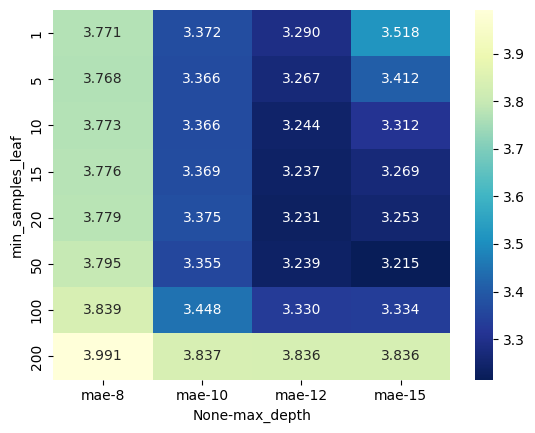

In [124]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f", cmap="YlGnBu_r")

In [125]:
from sklearn.tree import export_text

dt_final = DecisionTreeRegressor(max_depth=best_dt_depth, min_samples_leaf=best_dt_leaf, random_state=42)
dt_final.fit(X_train, y_train)

print(export_text(dt_final, feature_names=list(dv.get_feature_names_out()), max_depth=3))

|--- delivery_person_ratings <= 4.45
|   |--- order_hour <= 10.50
|   |   |--- delivery_person_age <= 29.50
|   |   |   |--- multiple_deliveries <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- multiple_deliveries >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- delivery_person_age >  29.50
|   |   |   |--- delivery_person_ratings <= 4.25
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- delivery_person_ratings >  4.25
|   |   |   |   |--- truncated branch of depth 2
|   |--- order_hour >  10.50
|   |   |--- traffic=low <= 0.50
|   |   |   |--- multiple_deliveries <= 2.50
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- multiple_deliveries >  2.50
|   |   |   |   |--- value: [47.82]
|   |   |--- traffic=low >  0.50
|   |   |   |--- distance_km <= 9.36
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- distance_km >  9.36
|   |   |   |   |--- truncated branch of depth 4
|--- delivery_person_ra

Text(0, 0.5, 'Validation MAE')

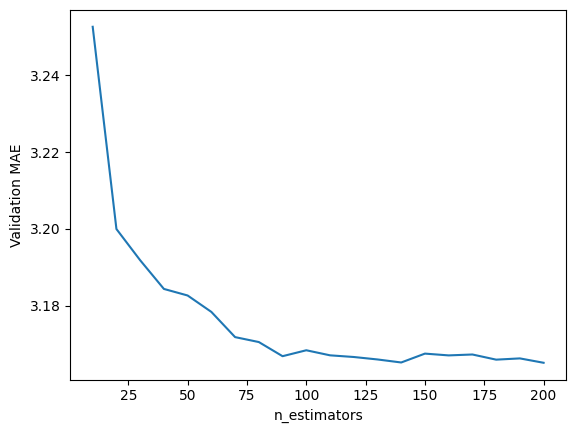

In [126]:
# 4.4 Random Forest
from sklearn.ensemble import RandomForestRegressor

scores = []

for n in range(10, 201, 10):
	rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
	rf.fit(X_train, y_train)

	y_pred = np.maximum(0.0, rf.predict(X_val))
	scores.append((n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['n_estimators', 'mae'])
plt.plot(df_scores.n_estimators, df_scores.mae)
plt.xlabel('n_estimators')
plt.ylabel('Validation MAE')


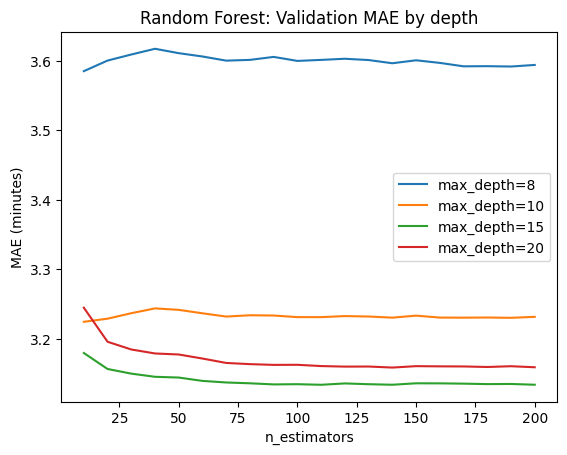

best max_depth: 15


In [127]:
scores = []

for d in [8, 10, 15, 20]:
	for n in range(10, 201, 10):
		rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
		rf.fit(X_train, y_train)
		y_pred = np.maximum(0.0, rf.predict(X_val))
		scores.append((d, n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'mae'])

for d in [8, 10, 15, 20]:
	df_subset = df_scores[df_scores.max_depth == d]
	plt.plot(df_subset.n_estimators, df_subset.mae, label='max_depth=%d' % d)

plt.xlabel('n_estimators')
plt.ylabel('MAE (minutes)')
plt.title('Random Forest: Validation MAE by depth')
plt.legend()
plt.show()

best_rf_depth = int(df_scores.loc[df_scores.mae.idxmin(), 'max_depth'])
print('best max_depth:', best_rf_depth)

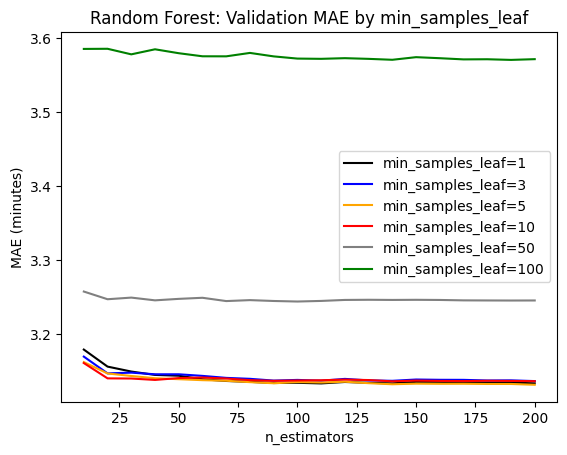

best min_samples_leaf: 5  n_estimators: 200


In [119]:
max_depth = best_rf_depth

scores = []

for s in [1, 3, 5, 10, 50, 100]:
	for n in range(10, 201, 10):
		rf = RandomForestRegressor(n_estimators=n, max_depth=max_depth, min_samples_leaf=s,
		                           random_state=1, n_jobs=-1)
		rf.fit(X_train, y_train)

		y_pred = np.maximum(0.0, rf.predict(X_val))
		scores.append((s, n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'mae'])

colors = ['black', 'blue', 'orange', 'red', 'grey', 'green']
values = [1, 3, 5, 10, 50, 100]

for s, col in zip(values, colors):
	df_subset = df_scores[df_scores.min_samples_leaf == s]
	plt.plot(df_subset.n_estimators, df_subset.mae, color=col, label='min_samples_leaf=%d' % s)

plt.xlabel('n_estimators')
plt.ylabel('MAE (minutes)')
plt.title('Random Forest: Validation MAE by min_samples_leaf')
plt.legend()
plt.show()

best_rf = df_scores.loc[df_scores.mae.idxmin()]
best_rf_leaf, best_rf_n = int(best_rf.min_samples_leaf), int(best_rf.n_estimators)
print('best min_samples_leaf:', best_rf_leaf, ' n_estimators:', best_rf_n)

In [120]:
rf = RandomForestRegressor(n_estimators=best_rf_n, max_depth=max_depth, min_samples_leaf=best_rf_leaf,
                           random_state=1, n_jobs=-1)

rf.fit(X_train, y_train)

y_pred = np.maximum(0.0, rf.predict(X_val))
print('Random Forest MAE:', mae(y_val, y_pred), ' RMSE:', rmse(y_val, y_pred))

Random Forest MAE: 3.1320305787956926  RMSE: 3.9527720977386136


In [128]:
# 4.5 XGBoost

import xgboost as xgb

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

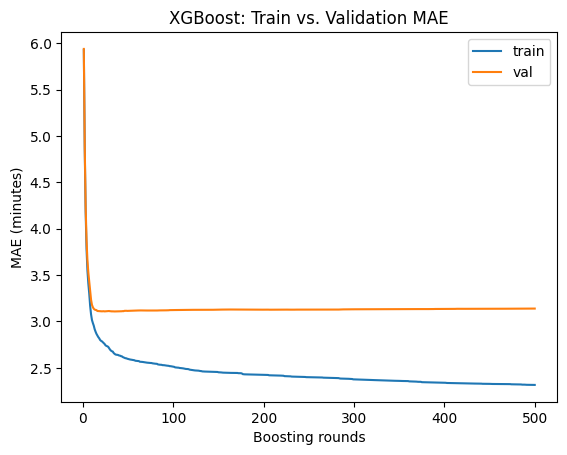

In [129]:
def train_xgb(params, num_boost_round=500):
  evals_result = {}
  model = xgb.train(params, dtrain, num_boost_round=num_boost_round, evals=watchlist,
                    evals_result=evals_result, verbose_eval=0)
  train_maes = evals_result['train']['mae']
  val_maes = evals_result['val']['mae']
  df_hist = pd.DataFrame({
    'iter': range(1, len(train_maes) + 1),
    'train_mae': train_maes,
    'val_mae': val_maes,
  })
  return model, df_hist

base_params = {
    'eta': 0.3,
    'max_depth': 8,
    'min_child_weight': 1,

    'objective': 'reg:absoluteerror',
    'eval_metric': 'mae',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model, df_hist = train_xgb(base_params)

plt.plot(df_hist.iter, df_hist.train_mae, label='train')
plt.plot(df_hist.iter, df_hist.val_mae, label='val')
plt.xlabel('Boosting rounds')
plt.ylabel('MAE (minutes)')
plt.title('XGBoost: Train vs. Validation MAE')
plt.legend()
plt.show()

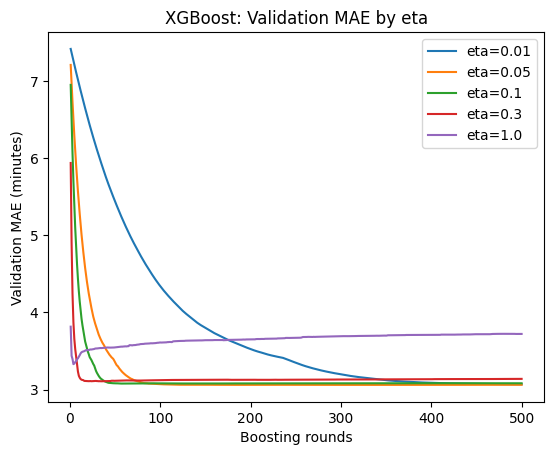

best eta: 0.05  val MAE: 3.06


In [130]:
scores = {}

for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    params = {**base_params, 'eta': eta}
    _, df_hist = train_xgb(params)
    scores[eta] = df_hist

for key, df_hist in scores.items():
    plt.plot(df_hist.iter, df_hist.val_mae, label=f'eta={key}')

plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by eta')
plt.legend()
plt.show()

best_eta = min(scores, key=lambda k: scores[k].val_mae.min())
print('best eta:', best_eta, ' val MAE:', round(scores[best_eta].val_mae.min(), 3))

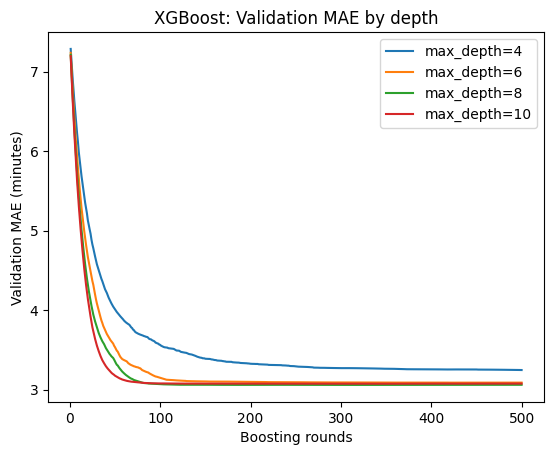

best max_depth: 8  val MAE: 3.06


In [131]:
scores = {}

for d in [4, 6, 8, 10]:
    params = {**base_params, 'eta': best_eta, 'max_depth': d}
    _, df_hist = train_xgb(params)
    scores[d] = df_hist

for key, df_hist in scores.items():
    plt.plot(df_hist.iter, df_hist.val_mae, label=f'max_depth={key}')

plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by depth')
plt.legend()
plt.show()

best_depth = min(scores, key=lambda k: scores[k].val_mae.min())
print('best max_depth:', best_depth, ' val MAE:', round(scores[best_depth].val_mae.min(), 3))

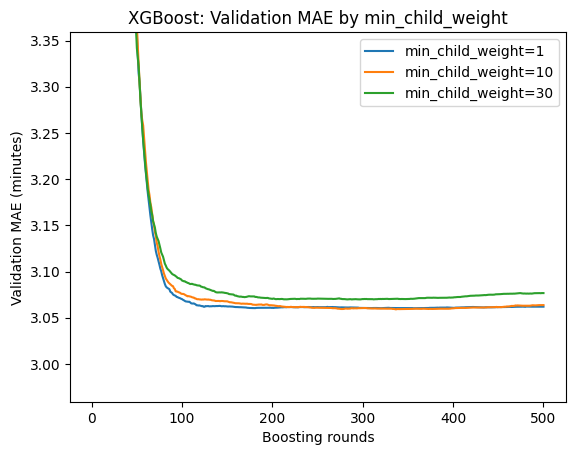

best min_child_weight: 10  val MAE: 3.059


In [132]:
scores = {}

for mcw in [1, 10, 30]:
    params = {**base_params, 'eta': best_eta, 'max_depth': best_depth,
              'min_child_weight': mcw}
    _, df_hist = train_xgb(params)
    scores[mcw] = df_hist

for key, df_hist in scores.items():
    plt.plot(df_hist.iter, df_hist.val_mae, label=f'min_child_weight={key}')

best_val = min(h.val_mae.min() for h in scores.values())
plt.ylim(best_val - 0.1, best_val + 0.3)
plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by min_child_weight')
plt.legend()
plt.show()

best_mcw = min(scores, key=lambda k: scores[k].val_mae.min())
print('best min_child_weight:', best_mcw, ' val MAE:', round(scores[best_mcw].val_mae.min(), 3))

In [134]:
final_params = {**base_params, 'eta': best_eta, 'max_depth': best_depth,
                'min_child_weight': best_mcw}

_, df_hist = train_xgb(final_params)
best_rounds = int(df_hist.loc[df_hist.val_mae.idxmin(), 'iter'])
print('Selected parameters:', {'eta': best_eta, 'max_depth': best_depth, 'min_child_weight': best_mcw}, ' best_rounds:', best_rounds)

model = xgb.train(final_params, dtrain, num_boost_round=best_rounds)

y_pred = np.maximum(0.0, model.predict(dval))
print('XGB val MAE:', mae(y_val, y_pred), ' RMSE:', rmse(y_val, y_pred))

Selected parameters: {'eta': 0.05, 'max_depth': 8, 'min_child_weight': 10}  best_rounds: 337
XGB val MAE: 3.0591336999696312  RMSE: 3.9064079626659214


In [135]:
# 4.6 Model comparison on the validation set

ridge = Ridge(alpha=best_alpha).fit(X_train_scaled, y_train)

val_predictions = {
    'median baseline': y_pred_baseline,
    'ridge': ridge.predict(X_val_scaled),
    'decision tree': dt_final.predict(X_val),
    'random forest': rf.predict(X_val),
    'xgboost': model.predict(dval),
}

df_compare = pd.DataFrame([
    {'model': name, 'val_mae': mae(y_val, np.maximum(0.0, p)), 'val_rmse': rmse(y_val, np.maximum(0.0, p))}
    for name, p in val_predictions.items()
]).sort_values('val_mae')
df_compare.round(3)

,model,val_mae,val_rmse
4,xgboost,3.059,3.906
3,random forest,3.159,3.994
2,decision tree,3.215,4.086
1,ridge,4.782,5.994
0,median baseline,7.470,9.276


**Model selection.** XGBoost has the lowest validation MAE (3.06 min) and RMSE (3.91)

# 5. Final Model Evaluation

In [136]:
dicts_full_train = df_full_train[numerical + categorical].to_dict(orient='records')
dicts_test = df_test[numerical + categorical].to_dict(orient='records')

dv_full = DictVectorizer(sparse=False)
X_full_train = dv_full.fit_transform(dicts_full_train)
X_test = dv_full.transform(dicts_test)

features = list(dv_full.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

model = xgb.train(final_params, dfulltrain, num_boost_round=best_rounds)

y_pred_test = np.maximum(0.0, model.predict(dtest))
y_baseline_test = np.repeat(np.median(y_full_train), len(y_test))
print('Final XGBoost Test MAE :', round(mae(y_test, y_pred_test), 3),
      ' | median baseline:', round(mae(y_test, y_baseline_test), 3))
print('Final XGBoost Test RMSE:', round(rmse(y_test, y_pred_test), 3),
      ' | median baseline:', round(rmse(y_test, y_baseline_test), 3))

df_importance = (pd.Series(model.get_score(importance_type='gain'), name='gain')
                   .sort_values(ascending=False))
display(df_importance.head(10))

Final XGBoost Test MAE : 3.148  | median baseline: 7.607
Final XGBoost Test RMSE: 3.969  | median baseline: 9.49


traffic=low                182.729034
weather=sunny               59.432472
traffic=medium              42.723240
festival=no                 31.975647
weather=fog                 30.281652
delivery_person_ratings     28.246223
weather=cloudy              27.193087
vehicle_condition           20.589901
multiple_deliveries         14.477320
traffic=jam                 12.890063
Name: gain, dtype: float64